# 02 · Model comparison and error analysis

scikit-learn token baseline vs fine-tuned DistilBERT, per-entity results, and the
inference backends (PyTorch / ONNX FP32 / ONNX INT8).

In [1]:
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
ner_m = json.loads((ROOT / "reports/ner_metrics.json").read_text())
sk_m = json.loads((ROOT / "reports/sk_token_baseline_metrics.json").read_text())
sec_m = json.loads((ROOT / "reports/secret_detector_metrics.json").read_text())
overall = pd.DataFrame({
    "sklearn baseline (LogReg, handcrafted features)": {k: sk_m["test"][k] for k in ("precision", "recall", "f1")},
    "DistilBERT fine-tuned (PyTorch)": {k: ner_m["test"][k] for k in ("precision", "recall", "f1")},
}).T
overall

,precision,recall,f1
"sklearn baseline (LogReg, handcrafted features)",0.8497,0.7102,0.7737
DistilBERT fine-tuned (PyTorch),0.9321,0.9606,0.9461


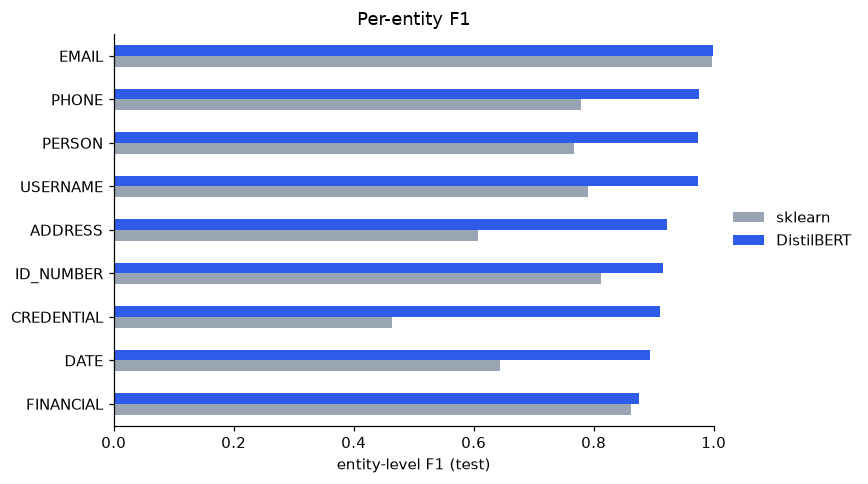

,sklearn,DistilBERT
FINANCIAL,0.863,0.875
DATE,0.643,0.893
CREDENTIAL,0.464,0.910
ID_NUMBER,0.812,0.915
ADDRESS,0.607,0.922
USERNAME,0.790,0.974
PERSON,0.768,0.974
PHONE,0.778,0.976
EMAIL,0.997,0.999


In [3]:
labels = [k for k in ner_m["test"]["per_entity"] if k.isupper()]
per = pd.DataFrame({
    "sklearn": {l: sk_m["test"]["per_entity"][l]["f1-score"] for l in labels},
    "DistilBERT": {l: ner_m["test"]["per_entity"][l]["f1-score"] for l in labels},
}).sort_values("DistilBERT")
ax = per.plot.barh(figsize=(8, 4.5), color=["#9aa5b4", "#2f5bea"])
ax.set_xlabel("entity-level F1 (test)"); ax.set_xlim(0, 1); ax.set_title("Per-entity F1")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)
plt.tight_layout(); plt.savefig(FIG / "per_entity_f1.png"); plt.show()
per.round(3)

## Calibration

Temperature scaling fitted on validation logits; ECE measured on test tokens.

In [4]:
ner_m['calibration']

{'temperature': 1.5136, 'ece_before': 0.0069, 'ece_after': 0.0023}

## Secret detector: in-distribution vs out-of-distribution

In [5]:
rows = {}
for name, m in sec_m["models"].items():
    for part in ("test", "challenge_ood"):
        rows[(name, part)] = {k: m[part][k] for k in ("precision", "recall", "f1", "average_precision")}
pd.DataFrame(rows).T

precision  recall      f1  average_precision
logreg test              0.9949  0.9993  0.9971             1.0000
       challenge_ood     1.0000  0.8433  0.9150             0.9732
hgb    test              1.0000  1.0000  1.0000             1.0000
       challenge_ood     1.0000  0.8473  0.9174             0.9461

The challenge set uses contexts and token formats that never appear in training
(e.g. GitLab `glpat-` tokens, keyword-free credentials). Remaining misses are
mostly 32-char hex secrets with no keyword nearby, which are indistinguishable
from MD5 hashes without context: a documented limitation.

## Inference backends

In [6]:
bench = json.loads((ROOT / "reports/benchmark.json").read_text())
pd.DataFrame(bench["summary"]).T

,f1,f1_by_source,f1_delta_vs_pytorch,p95_ms_batch1,speedup_p95_batch1,size_mb
pytorch_fp32_cpu,0.9472,"{'ai4privacy': 0.9277, 'synth': 0.9863}",0.0,117.66,1.0,260.8
onnx_fp32,0.9472,"{'ai4privacy': 0.9277, 'synth': 0.9863}",0.0,70.9,1.66,260.9
onnx_int8,0.9457,"{'ai4privacy': 0.923, 'synth': 0.9915}",-0.0015,19.67,5.98,65.6


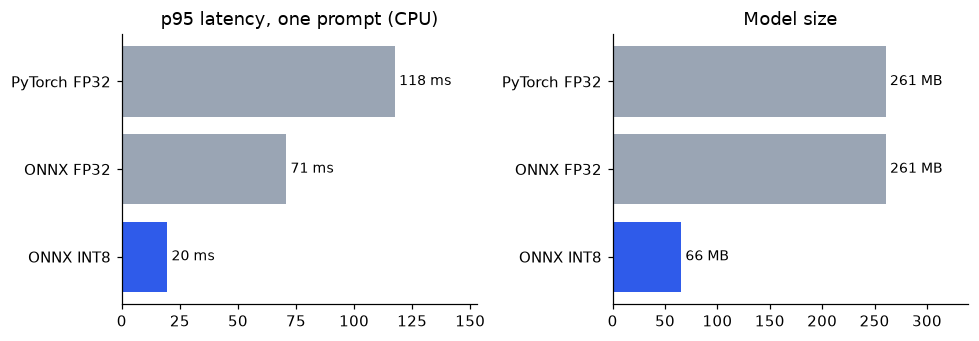

In [7]:
s = pd.DataFrame(bench["summary"]).T.loc[["pytorch_fp32_cpu", "onnx_fp32", "onnx_int8"]]
names = ["PyTorch FP32", "ONNX FP32", "ONNX INT8"]
colors = ["#9aa5b4", "#9aa5b4", "#2f5bea"]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, col, title, unit in [(axes[0], "p95_ms_batch1", "p95 latency, one prompt (CPU)", "ms"),
                             (axes[1], "size_mb", "Model size", "MB")]:
    vals = s[col].astype(float).values
    ax.barh(names, vals, color=colors)
    for i, v in enumerate(vals):
        ax.text(v, i, f" {v:.0f} {unit}", va="center", fontsize=9)
    ax.set_title(title); ax.set_xlim(0, vals.max() * 1.3); ax.invert_yaxis()
plt.tight_layout(); plt.savefig(FIG / "latency.png"); plt.show()

In [8]:
# throughput by batch size: on CPU, batch 1 wins (ORT already parallelises a single call)
pd.DataFrame([
    {"backend": b, "batch": l["batch"], "texts_per_sec": l["texts_per_sec"]}
    for b, r in bench["details"].items() for l in r["latency"]
]).pivot(index="batch", columns="backend", values="texts_per_sec")

backend,onnx_fp32,onnx_int8,pytorch_fp32_cpu
batch,,,
1,27.6,99.4,14.8
8,19.1,63.0,12.4
32,22.3,42.4,12.6
